# Optimal domain decomposition strategy

Using the built-in cartisian map to decompose the $N^3$ qube in an arbetrary dimension $n$ we investigate

- How many dimension should be decompose the domain in?
- Along which axis should we slice it?

**For $n=1$ we can decompose along 3 axis**

<div>
<img src="results/d1_a0.png" width="300"/>
<img src="results/d1_a1.png" width="300"/>
<img src="results/d1_a2.png" width="300"/>
</div>

**For $n=2$ we can decompose along a combination of axis with 3 different combinations**

<div>
<img src="results/d2_a01.png" width="300"/>
<img src="results/d2_a02.png" width="300"/>
<img src="results/d2_a12.png" width="300"/>
</div>

**For $n=3$ we there is only one option**

<div>
<img src="results/d3_a012.png" width="300"/>
</div>

Images are with $N=10$ and $6$ ranks for $n=1,2$ and $8$ ranks for for $n=3$

# Results

We run all the configurations for $N=500-1000$

In [27]:
import pandas as pd
import os
import matplotlib.pyplot as plt

# Concat all dfs into one
csv_list = os.listdir("results/my_results")
csv_list.sort()
df_list = []
for i in range(0, len(csv_list)):
    csv_path = "results/my_results/" + csv_list[i]
    df_list.append(pd.read_csv(csv_path))
df = pd.concat(df_list)

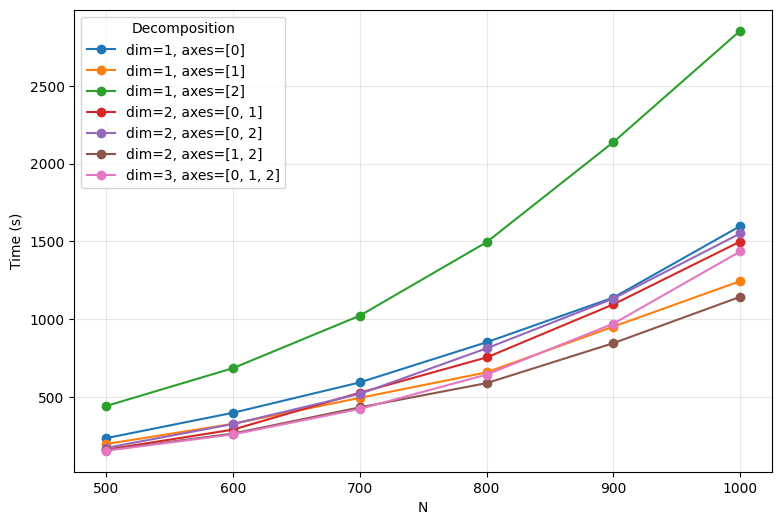

In [28]:
# Plot total calculation time
groups = df.groupby(["decomb_dim", "decomb_axes", "N"]).max()
plot_df = groups.reset_index()

fig, ax = plt.subplots(figsize=(9, 6))
for (decomb_dim, decomb_axes), data in plot_df.groupby(["decomb_dim", "decomb_axes"]):
    data = data.sort_values("N")
    ax.plot(
        data["N"],
        data["time"],
        marker="o",
        label=f"dim={decomb_dim}, axes={decomb_axes}",
    )

ax.set_xlabel("N")
ax.set_ylabel("Time (s)")
ax.legend(title="Decomposition")
ax.grid(True, alpha=0.3)
plt.show()